# Analysis of Results Common
Comparing individual `_best.csv` files against concatenated batch results, followed by iTRAQ Validation.

In [1]:
import pandas as pd
import glob
import os
import numpy as np
import ast
from scipy.stats import pearsonr, zscore
import joblib
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd # Ensure pandas is avail


In [2]:


RESULTS_DIR = "../results_val"


## 1. Load Individual `*_best.csv` Files

In [3]:

# Find all protein_best.csv files
best_files = glob.glob(os.path.join(RESULTS_DIR, "*_best.csv"))
print(f"Found {len(best_files)} individual best files.")

dfs = []
for f in best_files:
    try:
        df = pd.read_csv(f)
        dfs.append(df)
    except Exception as e:
        print(f"Error reading {f}: {e}")

if dfs:
    df_best_all = pd.concat(dfs, ignore_index=True)
    # Sort for consistency
    df_best_all.sort_values("protein", inplace=True)
    df_best_all.reset_index(drop=True, inplace=True)
    
    print(f"Concatenated Best Shape: {df_best_all.shape}")
    display(df_best_all.head())
else:
    df_best_all = pd.DataFrame()
    print("No best files loaded.")


Found 1809 individual best files.
Concatenated Best Shape: (1809, 10)


,protein,best_sample,best_abs_error,mse_all_others,params_dict,feat_coeffs_dict,zscore_genes,zscore_mu,zscore_sigma,zscore_eps
0,A2M,UMUC3_URINARY_TRACT,0.003011,0.836941,"{'alpha': 1.0, 'l1_ratio': 0.1}","{'A1BG': 0.0, 'A2M': 0.05601153568687824, 'AAD...","['A1BG', 'A2M', 'AADAT', 'AASS', 'ABCB6', 'ABI...","[2.821546846143207, 0.8868445119261132, 2.2698...","[2.051967442561821, 1.8051704733585499, 1.2569...",1.000000e-08
1,AARS2,SQ1_LUNG,0.000137,0.140420,"{'alpha': 0.1, 'l1_ratio': 0.5}","{'A2M': 0.0, 'AARS2': 0.15406732440684603, 'AA...","['A2M', 'AARS2', 'AATK', 'ABCC10', 'ABCG1', 'A...","[0.8871246572874287, 3.4942220091470135, 1.098...","[1.8050580488255072, 0.6163178413829652, 1.117...",1.000000e-08
2,AASDHPPT,HEC59_ENDOMETRIUM,0.000364,0.273664,"{'alpha': 0.1, 'l1_ratio': 0.9}","{'A4GALT': -0.0, 'AAAS': 0.0, 'AARS2': 0.0, 'A...","['A4GALT', 'AAAS', 'AARS2', 'AASDHPPT', 'ABCB1...","[2.103931763318877, 5.69152738256317, 3.493995...","[1.5504930921286346, 0.5083307393271205, 0.616...",1.000000e-08
3,ABCB7,SEM_HAEMATOPOIETIC_AND_LYMPHOID_TISSUE,0.000245,0.147214,"{'alpha': 0.1, 'l1_ratio': 0.5}","{'AASS': -0.0, 'ABCB6': -0.0, 'ABCB7': 0.22758...","['AASS', 'ABCB6', 'ABCB7', 'ABI3', 'ABL1', 'AC...","[2.029682970399025, 4.270079436520009, 4.11333...","[1.4572810773960054, 1.3446260392182268, 0.563...",1.000000e-08
4,ABCD3,CAL33_UPPER_AERODIGESTIVE_TRACT,0.000973,0.202043,"{'alpha': 0.1, 'l1_ratio': 0.5}","{'AAAS': -0.0, 'AASDHPPT': -0.0118042086846440...","['AAAS', 'AASDHPPT', 'ABCC3', 'ABCC6', 'ABCD3'...","[5.692029499779636, 4.809574950496353, 3.54140...","[0.5086774092766796, 0.610410849672823, 2.4961...",1.000000e-08


## 2. Load Batch Result Files

In [4]:

# Find batch files (assuming pattern results_batch_*.csv)
batch_files = glob.glob(os.path.join(RESULTS_DIR, "*batch*.csv"))
print(f"Found {len(batch_files)} batch files.")

dfs_batch = []
for f in batch_files:
    try:
        df = pd.read_csv(f)
        dfs_batch.append(df)
    except Exception as e:
        print(f"Error reading {f}: {e}")

if dfs_batch:
    df_batch_concat = pd.concat(dfs_batch, ignore_index=True)
    df_batch_concat.sort_values("protein", inplace=True)
    df_batch_concat.reset_index(drop=True, inplace=True)
    
    print(f"Concatenated Batch Shape: {df_batch_concat.shape}")
    display(df_batch_concat.head())
else:
    df_batch_concat = pd.DataFrame()
    print("No batch files loaded.")


Found 0 batch files.
No batch files loaded.


## 3. Compare

In [5]:

# Check if they are the same
if not df_best_all.empty and not df_batch_concat.empty:
    # 1. Compare protein lists
    prots_best = set(df_best_all['protein'].unique())
    prots_batch = set(df_batch_concat['protein'].unique())
    
    missing_in_batch = prots_best - prots_batch
    missing_in_best = prots_batch - prots_best
    
    print(f"Proteins in Best: {len(prots_best)}")
    print(f"Proteins in Batch: {len(prots_batch)}")
    
    if missing_in_batch:
        print(f"Proteins in Best but NOT in Batch: {len(missing_in_batch)}")
    if missing_in_best:
        print(f"Proteins in Batch but NOT in Best: {len(missing_in_best)}")
        
    # Check shape equality
    if df_best_all.shape == df_batch_concat.shape:
         try:
            pd.testing.assert_frame_equal(df_best_all, df_batch_concat, check_like=True)
            print("SUCCESS: DataFrames are identical (pd.testing.assert_frame_equal passed).")
         except AssertionError as e:
            print(f"DataFrames are NOT identical: {e}")
    else:
        print("Shapes differ, cannot be identical.")

else:
    print("Cannot compare - one or both dataframes are empty.")


Cannot compare - one or both dataframes are empty.


## 4. iTRAQ Data Loading (Pre-Processed with Gene Symbols)

In [6]:


# --- UPDATED: Load from Validation Folder ---
RNA_PATH = "../val_data/iTRAQ_transcriptomics.joblib"
PROT_PATH = "../val_data/iTRAQ_proteomics.joblib"

print(f"Loading Validation iTRAQ Data from: {RNA_PATH} and {PROT_PATH}")

rna_df = None
prot_df = None

if os.path.exists(RNA_PATH) and os.path.exists(PROT_PATH):
    try:
        rna_df = joblib.load(RNA_PATH)
        prot_df = joblib.load(PROT_PATH)
        
        # Ensure we have pandas DataFrames
        if not isinstance(rna_df, pd.DataFrame):
            print("Warning: Loaded RNA object is not a DataFrame.")
        if not isinstance(prot_df, pd.DataFrame):
            print("Warning: Loaded Protein object is not a DataFrame.")

        print(f"iTRAQ RNA Shape: {rna_df.shape}")
        print(f"iTRAQ Protein Shape: {prot_df.shape}")
        
        # Display heads if possible (requires IPython display which is avail in notebook)
        try:
            display(rna_df.head())
            display(prot_df.head())
        except:
            print(rna_df.head())
            print(prot_df.head())
        
    except Exception as e:
        print(f"Error loading joblib files: {e}")
else:
    print(f"Validation files not found. Current CWD: {os.getcwd()}")
    if not os.path.exists("../validation"):
        print("Folder ../validation does not exist.")


Loading Validation iTRAQ Data from: ../val_data/iTRAQ_transcriptomics.joblib and ../val_data/iTRAQ_proteomics.joblib
iTRAQ RNA Shape: (276, 14521)
iTRAQ Protein Shape: (276, 4994)


,A1BG,A2LD1,A2M,A4GALT,AAAS,AACS,AADAT,AAGAB,AAK1,AAMP,...,ZWILCH,ZWINT,ZXDA,ZXDB,ZXDC,ZYG11A,ZYG11B,ZYX,ZZEF1,ZZZ3
BREAST_2016_1,-0.508490,-1.153376,-1.202334,-1.131827,-0.979962,-1.053568,-0.421568,-1.096561,-0.545035,-0.911011,...,-0.653001,-0.747386,-1.103054,-0.979636,-0.766164,-0.615594,-0.994290,-0.795390,-1.049107,-0.804106
BREAST_2016_2,-1.403538,-0.756231,-0.457725,-1.147781,-0.860535,-0.783645,-0.520725,-0.819992,-0.649074,-0.853689,...,-0.650424,-0.515440,-1.182893,-0.931234,-0.827498,-0.787344,-0.752454,-0.515360,-1.217307,-0.894644
BREAST_2016_3,-1.287885,-0.622182,-1.042992,-1.149324,-0.848227,-0.803669,-0.608043,-0.892752,-0.537735,-0.811905,...,-0.827744,-0.576427,-1.135260,-0.771619,-0.969030,-0.505604,-0.907812,-0.796724,-1.013359,-0.971731
BREAST_2016_4,-0.114388,-0.883758,-1.105571,-1.053353,-0.802927,-0.789913,-1.205345,-0.723377,-0.414271,-0.889508,...,-0.835141,-0.952481,-1.035868,-0.648840,-0.810226,-0.874695,-0.857321,-0.763365,-1.031251,-0.939668
BREAST_2016_5,0.651495,-0.713868,-0.904117,-0.681492,-0.907404,-0.735935,-1.129354,-0.742782,-0.595072,-0.771374,...,-1.062123,-1.131220,-1.082182,-0.799317,-0.881124,-1.383115,-0.929644,-0.866392,-1.094638,-0.828779


,A1BG,A2M,AAAS,AACS,AAGAB,AAK1,AAMDC,AAMP,AAR2,AARS1,...,ZNF622,ZNF638,ZNF706,ZNFX1,ZNRD2,ZPR1,ZRANB2,ZW10,ZYX,ZZEF1
BREAST_2016_1,-0.276204,-0.118167,0.101829,-0.810685,-0.266070,-0.000101,-0.191153,-0.351803,0.257179,0.056575,...,0.088984,0.040194,0.356291,0.148699,-0.126940,0.112897,0.103823,0.034224,-0.067299,-0.071318
BREAST_2016_2,0.012541,-0.071965,0.380597,-0.541994,-0.208804,0.016704,-0.676732,-0.170876,0.236362,0.500851,...,-0.181782,-0.000815,0.256505,-0.038332,-0.074657,0.397509,0.074143,0.236130,0.359966,-0.115000
BREAST_2016_3,-0.053171,-0.041210,0.215213,0.140317,0.087933,0.059402,1.069025,-0.267589,0.075797,0.505984,...,0.237633,0.070140,0.651903,0.044124,-0.833700,-0.169475,-0.101060,-0.081433,-0.222453,0.071404
BREAST_2016_4,0.720578,0.451998,0.185805,-0.314043,-0.262920,0.445861,-0.543346,-0.176218,-0.018129,-0.191610,...,-0.218552,-0.344207,-0.522582,0.217655,0.315308,0.276647,-0.836253,-0.208207,0.301478,0.049417
BREAST_2016_5,-0.063286,-0.108584,-0.020991,-0.368222,0.040098,0.156871,0.279753,0.018045,0.083028,-0.212115,...,-0.123523,0.110721,0.145498,0.042057,-0.007682,0.165648,-0.077357,0.073272,0.382310,-0.078302


## 5. Check Features & Normalize

In [7]:

if rna_df is not None:
    # 1. SKIP Normalization (Data already normalized) - Just handle NaNs
    print("Skipping z-score normalization (data already normalized). Filling NaNs with 0...")
    
    # Just fill NaNs (crucial to prevent NaNs in prediction)
    rna_z = rna_df.fillna(0)
    
    print("NaNs filled with 0.")
    display(rna_z.head())
    
    # Check coverage
    if not df_best_all.empty:
        import ast
        example_coeffs = ast.literal_eval(df_best_all.iloc[0]['feat_coeffs_dict'])
        needed = list(example_coeffs.keys())
        present = [g for g in needed if g in rna_z.columns]
        print(f"Example Model ({df_best_all.iloc[0]['protein']}) feature coverage: {len(present)}/{len(needed)}")


Skipping z-score normalization (data already normalized). Filling NaNs with 0...
NaNs filled with 0.


,A1BG,A2LD1,A2M,A4GALT,AAAS,AACS,AADAT,AAGAB,AAK1,AAMP,...,ZWILCH,ZWINT,ZXDA,ZXDB,ZXDC,ZYG11A,ZYG11B,ZYX,ZZEF1,ZZZ3
BREAST_2016_1,-0.508490,-1.153376,-1.202334,-1.131827,-0.979962,-1.053568,-0.421568,-1.096561,-0.545035,-0.911011,...,-0.653001,-0.747386,-1.103054,-0.979636,-0.766164,-0.615594,-0.994290,-0.795390,-1.049107,-0.804106
BREAST_2016_2,-1.403538,-0.756231,-0.457725,-1.147781,-0.860535,-0.783645,-0.520725,-0.819992,-0.649074,-0.853689,...,-0.650424,-0.515440,-1.182893,-0.931234,-0.827498,-0.787344,-0.752454,-0.515360,-1.217307,-0.894644
BREAST_2016_3,-1.287885,-0.622182,-1.042992,-1.149324,-0.848227,-0.803669,-0.608043,-0.892752,-0.537735,-0.811905,...,-0.827744,-0.576427,-1.135260,-0.771619,-0.969030,-0.505604,-0.907812,-0.796724,-1.013359,-0.971731
BREAST_2016_4,-0.114388,-0.883758,-1.105571,-1.053353,-0.802927,-0.789913,-1.205345,-0.723377,-0.414271,-0.889508,...,-0.835141,-0.952481,-1.035868,-0.648840,-0.810226,-0.874695,-0.857321,-0.763365,-1.031251,-0.939668
BREAST_2016_5,0.651495,-0.713868,-0.904117,-0.681492,-0.907404,-0.735935,-1.129354,-0.742782,-0.595072,-0.771374,...,-1.062123,-1.131220,-1.082182,-0.799317,-0.881124,-1.383115,-0.929644,-0.866392,-1.094638,-0.828779


Example Model (A2M) feature coverage: 1194/1194


In [8]:

# 5.5 Setting up Analysis
print("\n=======================================================")
print(" PART 1: Analysis with ALL Tissues (No Filtering) ")
print("=======================================================\n")

# Note: Filtering will be done in Part 2 below.



 PART 1: Analysis with ALL Tissues (No Filtering) 



In [9]:

# --- CHECK PERCENTAGE OF ZEROS PER TISSUE ---
if 'rna_z' in locals() and not rna_z.empty:
    print("\n--- Percentage of Zeros per Tissue (RNA Data) ---")
    
    # Helper to get tissue from index (if not already defined)
    def get_tissue_check(idx):
        parts = idx.rsplit('_', 1)
        if len(parts) == 2 and parts[1].isdigit():
            return parts[0]
        return idx
    
    rna_zeros = rna_z.copy()
    rna_zeros['Tissue'] = [get_tissue_check(x) for x in rna_zeros.index]
    
    # Calculate % zeros: (Count of 0s / Total Cells) * 100
    zero_stats = rna_zeros.groupby('Tissue').apply(lambda x: (x.drop(columns='Tissue') == 0).sum().sum() / x.drop(columns='Tissue').size * 100)
    
    display(zero_stats.sort_values(ascending=False).to_frame(name="% Zeros"))
else:
    print("rna_z not found. Cannot check zeros.")
# --------------------------------------------



--- Percentage of Zeros per Tissue (RNA Data) ---


C:\Users\hp\AppData\Local\Temp\ipykernel_30464\1257190750.py:16: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  zero_stats = rna_zeros.groupby('Tissue').apply(lambda x: (x.drop(columns='Tissue') == 0).sum().sum() / x.drop(columns='Tissue').size * 100)


,% Zeros
Tissue,
BREAST_2016,6.438950
STOMACH_2019,5.178707
OVARY_2016,2.554920


## 6. Predict iTRAQ Proteins & Evaluate

In [10]:

# --- DEBUG: Feature Overlap Check ---
if rna_df is not None and not df_best_all.empty:
    print("Debugging Feature Coverage...")
    rna_feats = set(rna_df.columns)
    print(f"Total iTRAQ RNA Features: {len(rna_feats)}")
    
    # Check first 5 models
    for idx, row in df_best_all.head(5).iterrows():
        p_name = row['protein']
        coeffs = ast.literal_eval(row['feat_coeffs_dict'])
        needed = set(coeffs.keys())
        
        missing = needed - rna_feats
        present = needed & rna_feats
        
        print(f"Protein {p_name}: Needed {len(needed)}, Present {len(present)}, Missing {len(missing)}")
        if missing:
            print(f"  -> First 3 missing: {list(missing)[:3]}")
else:
    print("Data not loaded.")
# ------------------------------------


Debugging Feature Coverage...
Total iTRAQ RNA Features: 14521
Protein A2M: Needed 1194, Present 1194, Missing 0
Protein AARS2: Needed 1194, Present 1194, Missing 0
Protein AASDHPPT: Needed 1194, Present 1194, Missing 0
Protein ABCB7: Needed 1194, Present 1194, Missing 0
Protein ABCD3: Needed 1194, Present 1194, Missing 0


In [11]:

results = []
error_dict = {} # Key: Protein, Value: Series of errors (index=Sample)

if rna_df is not None and not df_best_all.empty:
    for idx, row in df_best_all.iterrows():
        p_name = row['protein']
        coeffs = ast.literal_eval(row['feat_coeffs_dict'])
        needed_feats = list(coeffs.keys())
        
        # Check target
        target_present = False
        y_true = None
        if p_name in prot_df.columns:
            target_present = True
            y_true = prot_df[p_name]
        
        # Check features
        missing = [f for f in needed_feats if f not in rna_z.columns]
        if missing:
            # print(f"Skipping {p_name}: missing {len(missing)} features")
            continue
            
        # Predict
        weights = np.array([coeffs[f] for f in needed_feats])
        X = rna_z[needed_feats]
        
        y_pred = X.dot(weights)
        
        mse = np.nan
        corr = np.nan
        cosine_sim = np.nan
        
        # Calculate Error Vector
        error_vector = None
        
        if target_present:
            common = y_pred.index.intersection(y_true.index)
            if len(common) > 2:
                yp = y_pred.loc[common]
                yt = y_true.loc[common]
                
                # Calculate errors for all common samples
                # error = predicted - actual
                error_vector = yp - yt
                
                valid = (~np.isnan(yp)) & (~np.isnan(yt))
                if valid.sum() > 2:
                    mse = np.mean((yp[valid] - yt[valid])**2)
                    corr, _ = pearsonr(yp[valid], yt[valid])
                    # Cosine Similarity
                    if np.linalg.norm(yp[valid]) > 0 and np.linalg.norm(yt[valid]) > 0:
                        cosine_sim = np.dot(yp[valid], yt[valid]) / (np.linalg.norm(yp[valid]) * np.linalg.norm(yt[valid]))
                    else:
                        cosine_sim = 0.0
        
        # Store error vector if it exists
        if error_vector is not None:
             error_dict[p_name] = error_vector
        
        results.append({
            "Protein": p_name,
            "MSE": mse,
            "Correlation": corr,
            "Cosine_Similarity": cosine_sim,
            "Target_Present": target_present
        })

    results_df = pd.DataFrame(results)
    print(f"Prediction complete for {len(results_df)} proteins.")
    display(results_df.head())
    
    if not results_df.empty:
        print("Average MSE:", results_df['MSE'].mean())
        print("Average Correlation:", results_df['Correlation'].mean())
    if 'Cosine_Similarity' in results_df.columns:
        print("Average Cosine Similarity:", results_df['Cosine_Similarity'].mean())

    # Create Error Table
    if error_dict:
        error_table = pd.DataFrame(error_dict).T # Proteins as Rows, Samples as Columns
        print("\nError Table (Predicted - Actual):")
        display(error_table.head())
    else:
        print("No error data collected.")
else:
    print("Cannot run prediction.")


Prediction complete for 1809 proteins.


,Protein,MSE,Correlation,Cosine_Similarity,Target_Present
0,A2M,0.751716,-0.183666,-0.182142,True
1,AARS2,0.072408,0.153240,0.153104,True
2,AASDHPPT,0.134484,0.014974,0.014974,True
3,ABCB7,0.119255,-0.022263,-0.022049,True
4,ABCD3,0.230317,0.421158,0.404561,True


Average MSE: 0.2576264148357149
Average Correlation: 0.1336496889692349
Average Cosine Similarity: 0.1261120820671123

Error Table (Predicted - Actual):


,BREAST_2016_1,BREAST_2016_2,BREAST_2016_3,BREAST_2016_4,BREAST_2016_5,BREAST_2016_6,BREAST_2016_7,BREAST_2016_8,BREAST_2016_9,BREAST_2016_10,...,STOMACH_2019_71,STOMACH_2019_72,STOMACH_2019_73,STOMACH_2019_74,STOMACH_2019_75,STOMACH_2019_76,STOMACH_2019_77,STOMACH_2019_78,STOMACH_2019_79,STOMACH_2019_80
A2M,-0.201132,-0.128980,-0.264182,-0.646058,-0.008015,-0.792039,-0.540870,-1.261902,0.351046,0.161368,...,0.376013,-1.057898,-0.887559,-0.826311,-1.201449,-2.218298,-1.068123,-0.542503,-0.407489,-0.764154
AARS2,0.159279,-0.011366,0.168567,-0.099453,0.191503,0.239466,0.001052,0.164258,-0.157471,0.055810,...,0.070201,0.468180,0.121658,0.183434,0.104213,0.338764,0.014715,0.237387,0.034216,0.147476
AASDHPPT,-0.326009,-0.538496,-0.081633,-0.569391,-0.251657,-0.534317,-0.711658,-0.198016,-0.278847,-0.285369,...,-0.243553,-0.187152,-0.394500,-0.236271,0.077406,0.007292,-0.239856,-0.033562,-0.118578,-0.140554
ABCB7,-0.127117,0.379343,0.169491,1.022244,0.358539,0.045186,0.639129,0.261471,0.565839,0.523117,...,0.189274,0.273397,-0.215225,-0.103235,-0.197438,0.504367,0.634910,0.290883,0.043801,-0.044636
ABCD3,0.508891,0.092404,-0.450484,0.976865,0.823299,-0.147539,0.983482,1.570133,1.065874,1.056202,...,-0.228987,0.243268,0.476940,0.176957,0.275529,0.740679,0.262425,-0.218958,0.027158,0.086145


In [12]:

# 7. Sorted Results & NaN Analysis
if 'results_df' in locals() and not results_df.empty:
    # Remove Target_Present if it exists
    df_display = results_df.copy()
    if "Target_Present" in df_display.columns:
        df_display = df_display.drop(columns=["Target_Present"])
    
    print("\n--- Top 10 by CORRELATION (Descending) ---")
    display(df_display.sort_values(by="Correlation", ascending=False).head(10))
    
    print("\n--- Top 10 by MSE (Ascending) ---")
    display(df_display.sort_values(by="MSE", ascending=True).head(10))
    
    if "Cosine_Similarity" in df_display.columns:
        print("\n--- Top 10 by COSINE SIMILARITY (Descending) ---")
        display(df_display.sort_values(by="Cosine_Similarity", ascending=False).head(10))
else:
    print("No protein results found.")

# Analyze NaNs in Error Table
if 'error_table' in locals() and not error_table.empty:
    total_nans = error_table.isna().sum().sum()
    print(f"\nTotal NaNs in Error Table: {total_nans}")
    
    if total_nans > 0:
        nan_prots = error_table.index[error_table.isna().any(axis=1)].tolist()
        print(f"Proteins with NaNs ({len(nan_prots)}): {nan_prots[:10]} ...")



--- Top 10 by CORRELATION (Descending) ---


,Protein,MSE,Correlation,Cosine_Similarity
494,EGFR,0.326443,0.727820,0.766067
20,ACADSB,0.428555,0.718494,0.654140
614,GAMT,0.312369,0.663323,0.734966
755,HYOU1,0.229924,0.657618,0.624084
1318,RNF213,0.115537,0.654373,0.653555
64,AGR2,0.946060,0.644372,0.678387
421,DHRS1,0.190170,0.643580,0.627139
89,ALCAM,0.489127,0.638554,0.566994
644,GLS,0.132101,0.633255,0.628526
913,MVK,0.109812,0.625395,0.633902



--- Top 10 by MSE (Ascending) ---


,Protein,MSE,Correlation,Cosine_Similarity
1227,PSMC5,0.023522,0.181481,0.180756
1228,PSMC6,0.024068,0.070388,0.069491
1224,PSMC2,0.024992,0.203139,0.193314
1223,PSMC1,0.025178,0.218271,0.214625
1410,RTCB,0.026131,0.275094,0.273148
1132,POLR2B,0.026337,0.015061,0.013207
1229,PSMD1,0.026475,0.079654,0.079246
1225,PSMC3,0.028946,-0.017533,-0.017451
1236,PSMD3,0.029090,0.077872,0.075746
407,DDX1,0.029804,0.318857,0.317764



--- Top 10 by COSINE SIMILARITY (Descending) ---


,Protein,MSE,Correlation,Cosine_Similarity
494,EGFR,0.326443,0.727820,0.766067
614,GAMT,0.312369,0.663323,0.734966
64,AGR2,0.946060,0.644372,0.678387
20,ACADSB,0.428555,0.718494,0.654140
1318,RNF213,0.115537,0.654373,0.653555
913,MVK,0.109812,0.625395,0.633902
644,GLS,0.132101,0.633255,0.628526
421,DHRS1,0.190170,0.643580,0.627139
755,HYOU1,0.229924,0.657618,0.624084
1654,TOM1L2,0.123452,0.574322,0.620824



Total NaNs in Error Table: 8469
Proteins with NaNs (78): ['ACSL5', 'ACY1', 'AGR2', 'AK4', 'AKAP1', 'AP3S1', 'APOO', 'ARHGEF12', 'ARPC3', 'CD99'] ...


In [13]:

# 8. Tissue Analysis (Worst Tissues by MSE)
if 'error_table' in locals() and not error_table.empty:
    def get_tissue(sample_name):
        # Name is everything before the final number
        # e.g., BRAIN_2021_1 -> BRAIN_2021
        parts = sample_name.rsplit('_', 1)
        if len(parts) == 2 and parts[1].isdigit():
            return parts[0]
        return sample_name # Fallback

    # Calculate Error^2 per sample (mean over proteins)
    # error_table shape: (Proteins x Samples)
    mse_per_sample = (error_table ** 2).mean(axis=0)
    
    # Create DataFrame mapping Sample -> Tissue
    tissue_data = []
    for sample, mse_val in mse_per_sample.items():
        tissue_data.append({
            "Sample": sample,
            "MSE": mse_val,
            "Tissue": get_tissue(sample)
        })
    
    tissue_df = pd.DataFrame(tissue_data)
    
    # Group by Tissue and compute mean MSE
    worst_tissues = tissue_df.groupby("Tissue")["MSE"].mean().sort_values(ascending=True)
    
    print("\n--- Best Tissues in terms of Error (Mean MSE) ---")
    display(worst_tissues.tail(10))
else:
    print("Error table not available for Tissue Analysis.")



--- Best Tissues in terms of Error (Mean MSE) ---


Tissue
BREAST_2016     0.215668
STOMACH_2019    0.261343
OVARY_2016      0.282286
Name: MSE, dtype: float64

In [14]:

# =======================================================
# PART 2: Analysis with FILTERED Tissues
# =======================================================

excluded_tissues = ['RENAL_2019', 'HEADNECK_2021', 'PANCREA2021']

if 'rna_z' in locals() and 'prot_df' in locals():
    def get_tissue_filter(sample_name):
        parts = sample_name.rsplit('_', 1)
        if len(parts) == 2 and parts[1].isdigit():
            return parts[0]
        return sample_name

    print(f"Original Samples: RNA={rna_z.shape[0]}, Prot={prot_df.shape[0]}")

    # Identify samples to remove
    samples_to_remove = []
    for s in rna_z.index:
        t = get_tissue_filter(s)
        if t in excluded_tissues:
            samples_to_remove.append(s)

    print(f"Removing {len(samples_to_remove)} samples from excluded tissues: {excluded_tissues}")

    # Filter in-place (or overwrite variable)
    # We overwrite rna_z and prot_df so the duplicated cells works as is
    rna_z = rna_z.drop(index=samples_to_remove, errors='ignore')
    prot_df = prot_df.drop(index=samples_to_remove, errors='ignore')

    print(f"Filtered Samples: RNA={rna_z.shape[0]}, Prot={prot_df.shape[0]}")

    # Print remaining tissues
    remaining_tissues = sorted(list(set([get_tissue_filter(s) for s in rna_z.index])))
    print(f"\nRemaining Tissues ({len(remaining_tissues)}): {remaining_tissues}")
else:
    print("Dataframes rna_z or prot_df not found.")


Original Samples: RNA=276, Prot=276
Removing 0 samples from excluded tissues: ['RENAL_2019', 'HEADNECK_2021', 'PANCREA2021']
Filtered Samples: RNA=276, Prot=276

Remaining Tissues (3): ['BREAST_2016', 'OVARY_2016', 'STOMACH_2019']


## 6. Predict iTRAQ Proteins & Evaluate

In [15]:

# --- DEBUG: Feature Overlap Check ---
if rna_df is not None and not df_best_all.empty:
    print("Debugging Feature Coverage...")
    rna_feats = set(rna_df.columns)
    print(f"Total iTRAQ RNA Features: {len(rna_feats)}")
    
    # Check first 5 models
    for idx, row in df_best_all.head(5).iterrows():
        p_name = row['protein']
        coeffs = ast.literal_eval(row['feat_coeffs_dict'])
        needed = set(coeffs.keys())
        
        missing = needed - rna_feats
        present = needed & rna_feats
        
        print(f"Protein {p_name}: Needed {len(needed)}, Present {len(present)}, Missing {len(missing)}")
        if missing:
            print(f"  -> First 3 missing: {list(missing)[:3]}")
else:
    print("Data not loaded.")
# ------------------------------------


Debugging Feature Coverage...
Total iTRAQ RNA Features: 14521
Protein A2M: Needed 1194, Present 1194, Missing 0
Protein AARS2: Needed 1194, Present 1194, Missing 0
Protein AASDHPPT: Needed 1194, Present 1194, Missing 0
Protein ABCB7: Needed 1194, Present 1194, Missing 0
Protein ABCD3: Needed 1194, Present 1194, Missing 0


In [16]:

results = []
error_dict = {} # Key: Protein, Value: Series of errors (index=Sample)

if rna_df is not None and not df_best_all.empty:
    for idx, row in df_best_all.iterrows():
        p_name = row['protein']
        coeffs = ast.literal_eval(row['feat_coeffs_dict'])
        needed_feats = list(coeffs.keys())
        
        # Check target
        target_present = False
        y_true = None
        if p_name in prot_df.columns:
            target_present = True
            y_true = prot_df[p_name]
        
        # Check features
        missing = [f for f in needed_feats if f not in rna_z.columns]
        if missing:
            # print(f"Skipping {p_name}: missing {len(missing)} features")
            continue
            
        # Predict
        weights = np.array([coeffs[f] for f in needed_feats])
        X = rna_z[needed_feats]
        
        y_pred = X.dot(weights)
        
        mse = np.nan
        corr = np.nan
        cosine_sim = np.nan
        
        # Calculate Error Vector
        error_vector = None
        
        if target_present:
            common = y_pred.index.intersection(y_true.index)
            if len(common) > 2:
                yp = y_pred.loc[common]
                yt = y_true.loc[common]
                
                # Calculate errors for all common samples
                # error = predicted - actual
                error_vector = yp - yt
                
                valid = (~np.isnan(yp)) & (~np.isnan(yt))
                if valid.sum() > 2:
                    mse = np.mean((yp[valid] - yt[valid])**2)
                    corr, _ = pearsonr(yp[valid], yt[valid])
                    # Cosine Similarity
                    if np.linalg.norm(yp[valid]) > 0 and np.linalg.norm(yt[valid]) > 0:
                        cosine_sim = np.dot(yp[valid], yt[valid]) / (np.linalg.norm(yp[valid]) * np.linalg.norm(yt[valid]))
                    else:
                        cosine_sim = 0.0
        
        # Store error vector if it exists
        if error_vector is not None:
             error_dict[p_name] = error_vector
        
        results.append({
            "Protein": p_name,
            "MSE": mse,
            "Correlation": corr,
            "Cosine_Similarity": cosine_sim,
            "Target_Present": target_present
        })

    results_df = pd.DataFrame(results)
    print(f"Prediction complete for {len(results_df)} proteins.")
    display(results_df.head())
    
    if not results_df.empty:
        print("Average MSE:", results_df['MSE'].mean())
        print("Average Correlation:", results_df['Correlation'].mean())
    if 'Cosine_Similarity' in results_df.columns:
        print("Average Cosine Similarity:", results_df['Cosine_Similarity'].mean())

    # Create Error Table
    if error_dict:
        error_table = pd.DataFrame(error_dict).T # Proteins as Rows, Samples as Columns
        print("\nError Table (Predicted - Actual):")
        display(error_table.head())
    else:
        print("No error data collected.")
else:
    print("Cannot run prediction.")


Prediction complete for 1809 proteins.


,Protein,MSE,Correlation,Cosine_Similarity,Target_Present
0,A2M,0.751716,-0.183666,-0.182142,True
1,AARS2,0.072408,0.153240,0.153104,True
2,AASDHPPT,0.134484,0.014974,0.014974,True
3,ABCB7,0.119255,-0.022263,-0.022049,True
4,ABCD3,0.230317,0.421158,0.404561,True


Average MSE: 0.2576264148357149
Average Correlation: 0.1336496889692349
Average Cosine Similarity: 0.1261120820671123

Error Table (Predicted - Actual):


,BREAST_2016_1,BREAST_2016_2,BREAST_2016_3,BREAST_2016_4,BREAST_2016_5,BREAST_2016_6,BREAST_2016_7,BREAST_2016_8,BREAST_2016_9,BREAST_2016_10,...,STOMACH_2019_71,STOMACH_2019_72,STOMACH_2019_73,STOMACH_2019_74,STOMACH_2019_75,STOMACH_2019_76,STOMACH_2019_77,STOMACH_2019_78,STOMACH_2019_79,STOMACH_2019_80
A2M,-0.201132,-0.128980,-0.264182,-0.646058,-0.008015,-0.792039,-0.540870,-1.261902,0.351046,0.161368,...,0.376013,-1.057898,-0.887559,-0.826311,-1.201449,-2.218298,-1.068123,-0.542503,-0.407489,-0.764154
AARS2,0.159279,-0.011366,0.168567,-0.099453,0.191503,0.239466,0.001052,0.164258,-0.157471,0.055810,...,0.070201,0.468180,0.121658,0.183434,0.104213,0.338764,0.014715,0.237387,0.034216,0.147476
AASDHPPT,-0.326009,-0.538496,-0.081633,-0.569391,-0.251657,-0.534317,-0.711658,-0.198016,-0.278847,-0.285369,...,-0.243553,-0.187152,-0.394500,-0.236271,0.077406,0.007292,-0.239856,-0.033562,-0.118578,-0.140554
ABCB7,-0.127117,0.379343,0.169491,1.022244,0.358539,0.045186,0.639129,0.261471,0.565839,0.523117,...,0.189274,0.273397,-0.215225,-0.103235,-0.197438,0.504367,0.634910,0.290883,0.043801,-0.044636
ABCD3,0.508891,0.092404,-0.450484,0.976865,0.823299,-0.147539,0.983482,1.570133,1.065874,1.056202,...,-0.228987,0.243268,0.476940,0.176957,0.275529,0.740679,0.262425,-0.218958,0.027158,0.086145


In [17]:

# 7. Sorted Results & NaN Analysis
if 'results_df' in locals() and not results_df.empty:
    # Remove Target_Present if it exists
    df_display = results_df.copy()
    if "Target_Present" in df_display.columns:
        df_display = df_display.drop(columns=["Target_Present"])
    
    print("\n--- Top 10 by CORRELATION (Descending) ---")
    display(df_display.sort_values(by="Correlation", ascending=False).head(10))
    
    print("\n--- Top 10 by MSE (Ascending) ---")
    display(df_display.sort_values(by="MSE", ascending=True).head(10))
    
    if "Cosine_Similarity" in df_display.columns:
        print("\n--- Top 10 by COSINE SIMILARITY (Descending) ---")
        display(df_display.sort_values(by="Cosine_Similarity", ascending=False).head(10))
else:
    print("No protein results found.")

# Analyze NaNs in Error Table
if 'error_table' in locals() and not error_table.empty:
    total_nans = error_table.isna().sum().sum()
    print(f"\nTotal NaNs in Error Table: {total_nans}")
    
    if total_nans > 0:
        nan_prots = error_table.index[error_table.isna().any(axis=1)].tolist()
        print(f"Proteins with NaNs ({len(nan_prots)}): {nan_prots[:10]} ...")



--- Top 10 by CORRELATION (Descending) ---


,Protein,MSE,Correlation,Cosine_Similarity
494,EGFR,0.326443,0.727820,0.766067
20,ACADSB,0.428555,0.718494,0.654140
614,GAMT,0.312369,0.663323,0.734966
755,HYOU1,0.229924,0.657618,0.624084
1318,RNF213,0.115537,0.654373,0.653555
64,AGR2,0.946060,0.644372,0.678387
421,DHRS1,0.190170,0.643580,0.627139
89,ALCAM,0.489127,0.638554,0.566994
644,GLS,0.132101,0.633255,0.628526
913,MVK,0.109812,0.625395,0.633902



--- Top 10 by MSE (Ascending) ---


,Protein,MSE,Correlation,Cosine_Similarity
1227,PSMC5,0.023522,0.181481,0.180756
1228,PSMC6,0.024068,0.070388,0.069491
1224,PSMC2,0.024992,0.203139,0.193314
1223,PSMC1,0.025178,0.218271,0.214625
1410,RTCB,0.026131,0.275094,0.273148
1132,POLR2B,0.026337,0.015061,0.013207
1229,PSMD1,0.026475,0.079654,0.079246
1225,PSMC3,0.028946,-0.017533,-0.017451
1236,PSMD3,0.029090,0.077872,0.075746
407,DDX1,0.029804,0.318857,0.317764



--- Top 10 by COSINE SIMILARITY (Descending) ---


,Protein,MSE,Correlation,Cosine_Similarity
494,EGFR,0.326443,0.727820,0.766067
614,GAMT,0.312369,0.663323,0.734966
64,AGR2,0.946060,0.644372,0.678387
20,ACADSB,0.428555,0.718494,0.654140
1318,RNF213,0.115537,0.654373,0.653555
913,MVK,0.109812,0.625395,0.633902
644,GLS,0.132101,0.633255,0.628526
421,DHRS1,0.190170,0.643580,0.627139
755,HYOU1,0.229924,0.657618,0.624084
1654,TOM1L2,0.123452,0.574322,0.620824



Total NaNs in Error Table: 8469
Proteins with NaNs (78): ['ACSL5', 'ACY1', 'AGR2', 'AK4', 'AKAP1', 'AP3S1', 'APOO', 'ARHGEF12', 'ARPC3', 'CD99'] ...


In [18]:

# 8. Tissue Analysis (Worst Tissues by MSE)
if 'error_table' in locals() and not error_table.empty:
    def get_tissue(sample_name):
        # Name is everything before the final number
        # e.g., BRAIN_2021_1 -> BRAIN_2021
        parts = sample_name.rsplit('_', 1)
        if len(parts) == 2 and parts[1].isdigit():
            return parts[0]
        return sample_name # Fallback

    # Calculate Error^2 per sample (mean over proteins)
    # error_table shape: (Proteins x Samples)
    mse_per_sample = (error_table ** 2).mean(axis=0)
    
    # Create DataFrame mapping Sample -> Tissue
    tissue_data = []
    for sample, mse_val in mse_per_sample.items():
        tissue_data.append({
            "Sample": sample,
            "MSE": mse_val,
            "Tissue": get_tissue(sample)
        })
    
    tissue_df = pd.DataFrame(tissue_data)
    
    # Group by Tissue and compute mean MSE
    worst_tissues = tissue_df.groupby("Tissue")["MSE"].mean().sort_values(ascending=True)
    
    print("\n--- Best Tissues in terms of Error (Mean MSE) ---")
    display(worst_tissues.tail(10))
else:
    print("Error table not available for Tissue Analysis.")



--- Best Tissues in terms of Error (Mean MSE) ---


Tissue
BREAST_2016     0.215668
STOMACH_2019    0.261343
OVARY_2016      0.282286
Name: MSE, dtype: float64


--- Global Performance Metrics ---



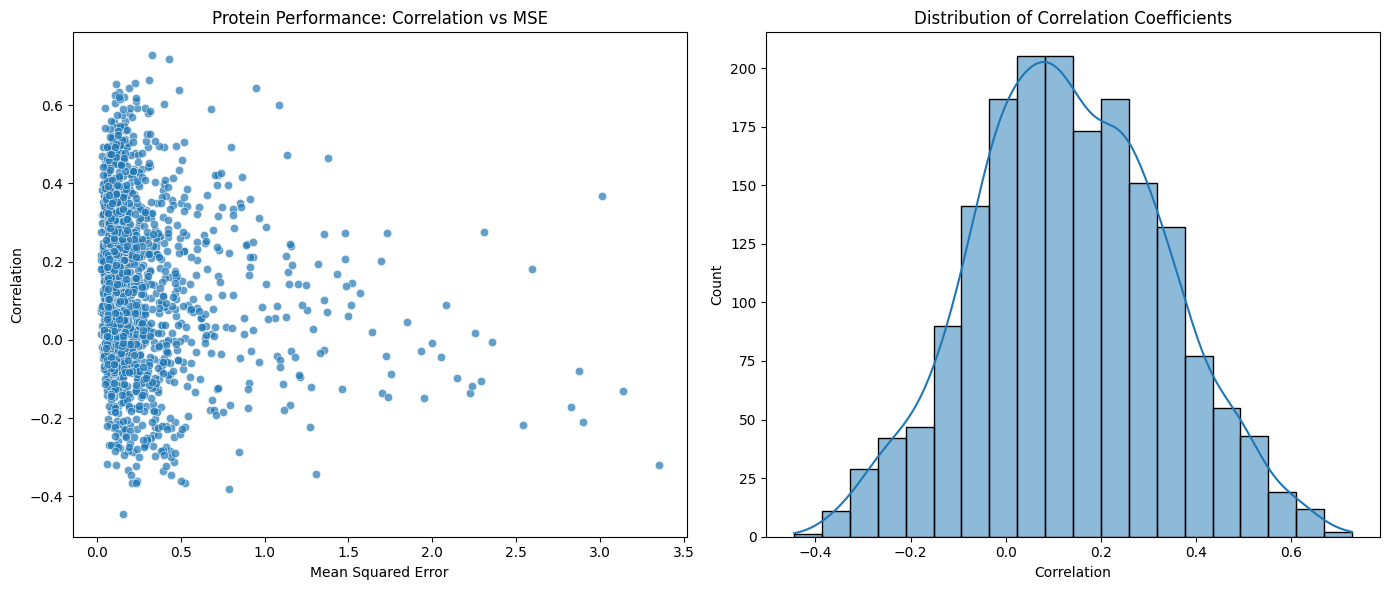

In [19]:

# 10. Global Visualizations

if 'results_df' in locals() and not results_df.empty:
    print("\n--- Global Performance Metrics ---\n")
    
    plt.figure(figsize=(14, 6))
    
    # 1. Correlation vs MSE Scatter
    plt.subplot(1, 2, 1)
    sns.scatterplot(data=results_df, x='MSE', y='Correlation', alpha=0.7)
    plt.title('Protein Performance: Correlation vs MSE')
    plt.xlabel('Mean Squared Error')
    plt.ylabel('Correlation')
    
    # 2. Correlation Distribution
    plt.subplot(1, 2, 2)
    sns.histplot(results_df['Correlation'], bins=20, kde=True)
    plt.title('Distribution of Correlation Coefficients')
    plt.xlabel('Correlation')
    
    plt.tight_layout()
    plt.show()



--- Tissue Performance Comparison ---



C:\Users\hp\AppData\Local\Temp\ipykernel_30464\3732386305.py:14: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=tissue_means.values, y=tissue_means.index, palette=colors)


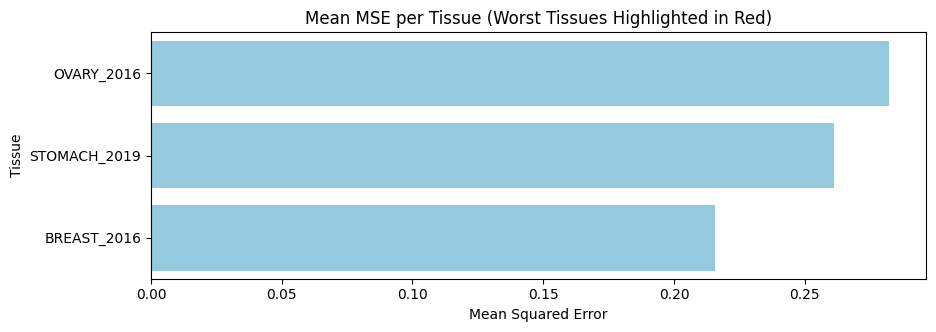

In [20]:

# 11. Tissue Performance Visualization
if 'tissue_df' in locals() and not tissue_df.empty:
    print("\n--- Tissue Performance Comparison ---\n")
    
    # Calculate mean MSE per tissue
    tissue_means = tissue_df.groupby("Tissue")["MSE"].mean().sort_values(ascending=False)
    
    plt.figure(figsize=(10, len(tissue_means) * 0.4 + 2))
    
    # Highlight worst tissues
    worst_targets = ['RENAL_2019', 'HEADNECK_2021', 'PANCREA2021']
    colors = ['red' if t in worst_targets else 'skyblue' for t in tissue_means.index]
    
    sns.barplot(x=tissue_means.values, y=tissue_means.index, palette=colors)
    plt.title("Mean MSE per Tissue (Worst Tissues Highlighted in Red)")
    plt.xlabel("Mean Squared Error")
    plt.show()
